# 🧠 Clasificación de imágenes con una Red Neuronal Convolucional (CNN)
## Proyecto Deep Learning — Dataset CIFAR-10

Este notebook de experimentación reproduce **el pipeline completo** del proyecto:

| Etapa | Contenido |
|---|---|
| 1 | Selección y descripción del dataset |
| 2 | Exploración y visualización de las imágenes |
| 3 | Preprocesamiento y normalización |
| 4 | División en entrenamiento / validación / prueba |
| 5 | Data augmentation |
| 6 | Construcción de la CNN |
| 7 | Entrenamiento |
| 8 | Métricas de evaluación |
| 9 | Gráficas del entrenamiento |
| 10 | Matriz de confusión |
| 11 | Predicciones de ejemplo (≥ 10 imágenes) |
| 12 | Guardado del modelo entrenado |
| 13 | Predicción sobre una imagen libre |

> **Cómo ejecutarlo en Google Colab:** `Entorno de ejecución → Ejecutar todo`.
> El notebook detecta automáticamente si hay GPU y ajusta el dispositivo.
>
> El código de este notebook es el **mismo** que el del paquete `src/` del
> repositorio: si el repositorio está disponible (clonado por `git clone` o
> montado en Drive) se importan sus módulos; si no, se usa la implementación
> local equivalente incluida más abajo.

In [1]:
# @title 0. Dependencias y hardware
import importlib.util
import subprocess
import sys

PAQUETES = {
    "torch": "torch",
    "torchvision": "torchvision",
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "PIL": "pillow",
    "tqdm": "tqdm",
}

faltantes = [paquete for modulo, paquete in PAQUETES.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    print(f"Instalando: {', '.join(faltantes)}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltantes], check=True)
else:
    print("Todas las dependencias ya están instaladas.")

import torch

print(f"PyTorch .............. {torch.__version__}")
print(f"GPU disponible ....... {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU .................. {torch.cuda.get_device_name(0)}")
    print(f"memoria CUDA ......... {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo de trabajo  {DEVICE}")

Todas las dependencias ya están instaladas.


PyTorch .............. 2.15.0+cpu
GPU disponible ....... False
Dispositivo de trabajo  cpu


In [2]:
# @title 0.1 Enlace con el repositorio (paquete `src`)
import os
import pathlib
import subprocess

URL_REPOSITORIO = "https://github.com/Alejo0916/Red_Neuronal_Convolucional.git"


def encontrar_raiz(inicio: pathlib.Path) -> pathlib.Path | None:
    """Sube en el árbol de directorios buscando el paquete `src`."""
    for candidato in [inicio, *inicio.parents]:
        if (candidato / "src" / "config.py").exists():
            return candidato
    return None


RAIZ = encontrar_raiz(pathlib.Path.cwd())
if RAIZ is None:
    print("Paquete `src` no encontrado; intentando clonar el repositorio...")
    try:
        subprocess.run(["git", "clone", "--depth", "1", URL_REPOSITORIO, "repo"], check=True)
        RAIZ = pathlib.Path.cwd() / "repo"
    except Exception as error:  # noqa: BLE001
        print(f"No se pudo clonar el repositorio ({error}).")
        RAIZ = None

if RAIZ is not None:
    sys.path.insert(0, str(RAIZ))
    os.chdir(RAIZ)
    print(f"Raíz del proyecto: {RAIZ}")

HAY_SRC = False
try:
    from src import config as src_config
    from src import data as src_data
    from src import evaluate as src_evaluate
    from src import model as src_model
    from src import predict as src_predict
    from src import train as src_train

    HAY_SRC = True
except Exception as error:  # noqa: BLE001
    print(f"Usando la implementación local del notebook ({error}).")

Raíz del proyecto: C:\Users\User\Documents\GitHub\Red_Neuronal_Convolucional


## 1. Selección y descripción del dataset

**Dataset elegido: CIFAR-10** (Krizhevsky, 2009).

- **60 000 imágenes** RGB de **32 × 32 píxeles**.
- **10 clases**: avión, automóvil, pájaro, gato, ciervo, perro, rana, caballo, barco, camión.
- **50 000** imágenes de entrenamiento y **10 000** de prueba, balanceadas (6 000 / 1 000 por clase).
- Formato: objetos centricados sobre un fondo uniforme, sin segmentación.
- **Licencia:** uso académico libre (http://www.cs.toronto.edu/~kriz/cifar.html).

Es el benchmark de referencia para CNN: imágenes de baja resolución que permiten
entrenar redes convolucionales profundas en minutos y analizar el comportamiento
del modelo (sobreajuste, curvas, confusiones entre clases).

In [3]:
# @title 1. Descarga y descripción del dataset
import numpy as np
import pandas as pd
from torchvision.datasets import CIFAR10

RAIZ_DATOS = pathlib.Path(RAIZ) / "data" if RAIZ is not None else pathlib.Path("data")
RAIZ_DATOS.mkdir(parents=True, exist_ok=True)

train_set = CIFAR10(root=str(RAIZ_DATOS), train=True, download=True)
test_set = CIFAR10(root=str(RAIZ_DATOS), train=False, download=True)

print(f"Entrenamiento: {len(train_set):,} imágenes")
print(f"Prueba:       {len(test_set):,} imágenes")
print(f"Forma:        {train_set.data.shape}  (N, H, W, C)")
print(f"Tipo:         {train_set.data.dtype}  -> rango [{train_set.data.min()}, {train_set.data.max()}]")
print(f"Clases:       {train_set.classes}")

Entrenamiento: 50,000 imágenes
Prueba:       10,000 imágenes
Forma:        (50000, 32, 32, 3)  (N, H, W, C)
Tipo:         uint8  -> rango [0, 255]
Clases:       ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [4]:
# @title 1.1 Descripción tabular del dataset
conteo_train = pd.Series(train_set.targets).value_counts().sort_index()
conteo_test = pd.Series(test_set.targets).value_counts().sort_index()

tabla = pd.DataFrame(
    {
        "entrenamiento": conteo_train,
        "prueba": conteo_test,
        "total": conteo_train + conteo_test,
    }
)
tabla.index.name = "clase"
tabla["proporcion"] = (tabla["total"] / tabla["total"].sum()).round(4)
display(tabla)
print(f"Dataset balanceado: {bool(tabla['total'].min() == tabla['total'].max())}")
print(f"Media global de píxeles: {train_set.data.mean() / 255:.4f}")

,entrenamiento,prueba,total,proporcion
clase,,,,
0,5000,1000,6000,0.1
1,5000,1000,6000,0.1
2,5000,1000,6000,0.1
3,5000,1000,6000,0.1
4,5000,1000,6000,0.1
5,5000,1000,6000,0.1
6,5000,1000,6000,0.1
7,5000,1000,6000,0.1
8,5000,1000,6000,0.1


Dataset balanceado: True
Media global de píxeles: 0.4734


## 2. Exploración y visualización de las imágenes

Tres visualizaciones que conviene hacer del dataset antes de entrenar:

1. **Rejilla de muestras por clase** — para verificar que las clases son distinguibles visualmente.
2. **Distribución de clases** — para detectar desbalances que sesgarían el entrenamiento.
3. **Preprocesamiento paso a paso** — de los valores originales 0-255 a la imagen normalizada.

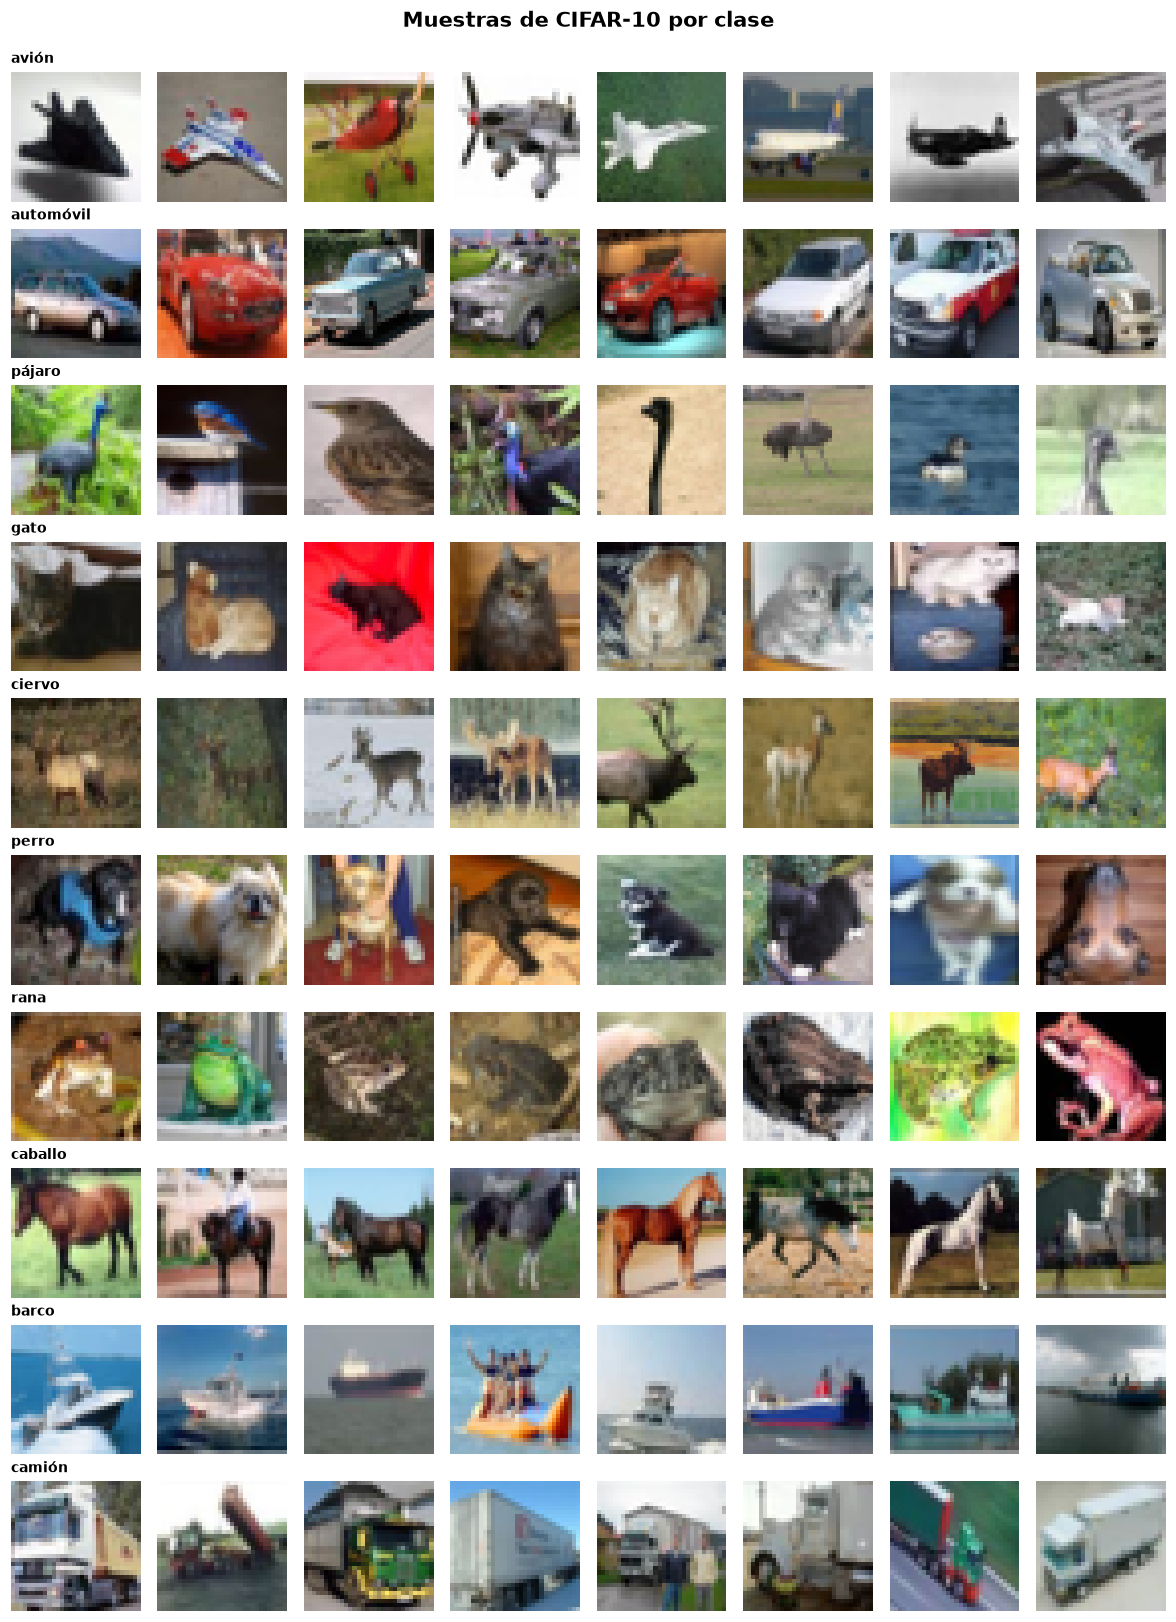

In [5]:
# @title 2. Visualización del dataset
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 10})

CLASES = ["avión", "automóvil", "pájaro", "gato", "ciervo", "perro", "rana", "caballo", "barco", "camión"]


def mostrar_muestras(dataset, muestras_por_clase=8):
    """Rejilla con muestras de cada clase."""
    por_clase = {}
    for indice, etiqueta in enumerate(dataset.targets):
        por_clase.setdefault(int(etiqueta), []).append(indice)

    filas = len(CLASES)
    figura, ejes = plt.subplots(filas, muestras_por_clase, figsize=(muestras_por_clase * 1.35, filas * 1.5))
    for fila in range(filas):
        indices = por_clase.get(fila, [])[:muestras_por_clase]
        for columna in range(muestras_por_clase):
            eje = ejes[fila, columna]
            eje.axis("off")
            if columna < len(indices):
                eje.imshow(dataset.data[indices[columna]])
                if columna == 0:
                    eje.set_title(CLASES[fila], fontsize=9, loc="left", fontweight="bold")
    figura.suptitle("Muestras de CIFAR-10 por clase", fontsize=14, fontweight="bold")
    figura.tight_layout(rect=(0, 0, 1, 0.985))
    plt.show()


mostrar_muestras(train_set)

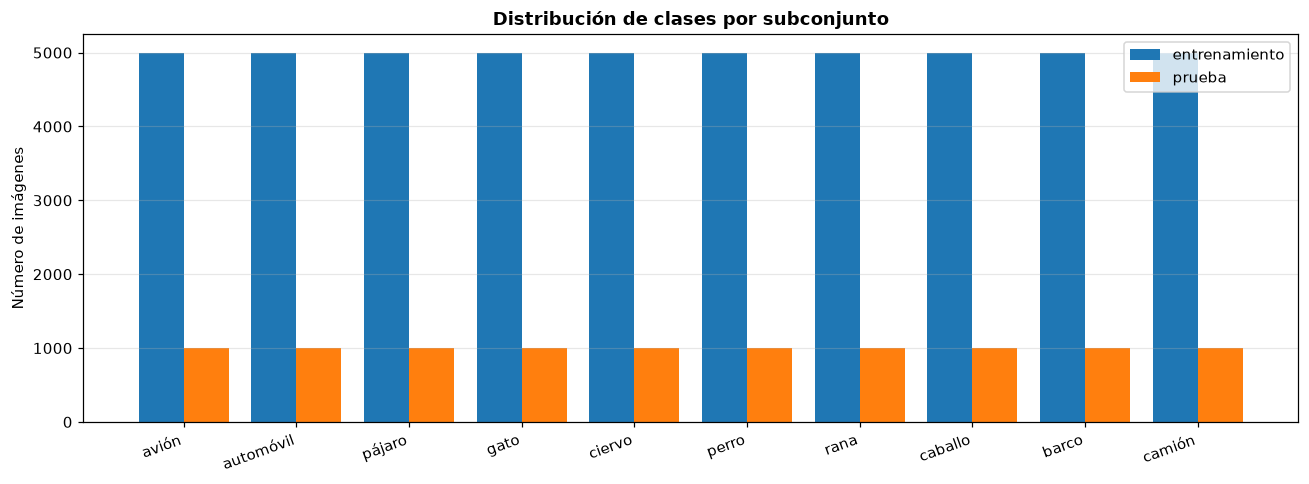

Distribución por clase (entrenamiento):
{0: 5000, 1: 5000, 2: 5000, 3: 5000, 4: 5000, 5: 5000, 6: 5000, 7: 5000, 8: 5000, 9: 5000}

El dataset está balanceado, por lo que la accuracy será una métrica representativa.


In [6]:
# @title 2.1 Distribución de clases y balance
figura, eje = plt.subplots(figsize=(12, 4.5))
posiciones = np.arange(len(CLASES))
eje.bar(posiciones - 0.2, [conteo_train.get(i, 0) for i in range(10)], 0.4, label="entrenamiento")
eje.bar(posiciones + 0.2, [conteo_test.get(i, 0) for i in range(10)], 0.4, label="prueba")
eje.set_xticks(posiciones)
eje.set_xticklabels(CLASES, rotation=20, ha="right")
eje.set_ylabel("Número de imágenes")
eje.set_title("Distribución de clases por subconjunto", fontweight="bold")
eje.legend()
eje.grid(axis="y", alpha=0.3)
figura.tight_layout()
plt.show()

print("Distribución por clase (entrenamiento):")
print(conteo_train.to_dict())
print("\nEl dataset está balanceado, por lo que la accuracy será una métrica representativa.")

## 3. Preprocesamiento y normalización

Cada imagen pasa por:

1. **Augmentation** (solo en entrenamiento): recorte aleatorio con relleno de 4 px + volteo horizontal.
2. **`ToTensor()`**: de `uint8 [0, 255]` a `float32 [0, 1]`, con formato `CHW`.
3. **Normalización por canal**: `x = (x - media) / desviación`, con la media y la desviación
   calculadas **únicamente sobre el subconjunto de entrenamiento** (evita fuga de información).

In [7]:
# @title 3. Estadísticas de normalización (solo sobre el train split)
from torchvision import transforms

MEDIA, DESVIACION = src_config.DEFAULT_MEAN, src_config.DEFAULT_STD

if HAY_SRC:
    from sklearn.model_selection import StratifiedShuffleSplit

    indices = np.arange(len(train_set))
    separador = StratifiedShuffleSplit(n_splits=1, test_size=5000, random_state=42)
    idx_train, idx_val = next(separador.split(indices, np.asarray(train_set.targets)))
    MEDIA, DESVIACION = src_data.compute_channel_stats(train_set, idx_train.tolist())

datos = train_set.data[idx_train].astype(np.float64) / 255.0
print("Estadísticas calculadas sobre", len(idx_train), "imágenes de entrenamiento")
print("media por canal  :", np.round(datos.mean(axis=(0, 1, 2)), 4))
print("desviación canal :", np.round(datos.std(axis=(0, 1, 2)), 4))
print("canal R difiere de G/B:", round(float(abs(datos.mean(axis=(0, 1, 2))[0] - datos.mean(axis=(0, 1, 2))[1])), 4))

[19:26:13] INFO | Calculando estadísticas de normalización sobre 45000 imágenes...


Estadísticas calculadas sobre 45000 imágenes de entrenamiento
media por canal  : [0.4911 0.4821 0.4464]


desviación canal : [0.2469 0.2434 0.2616]


canal R difiere de G/B: 0.009


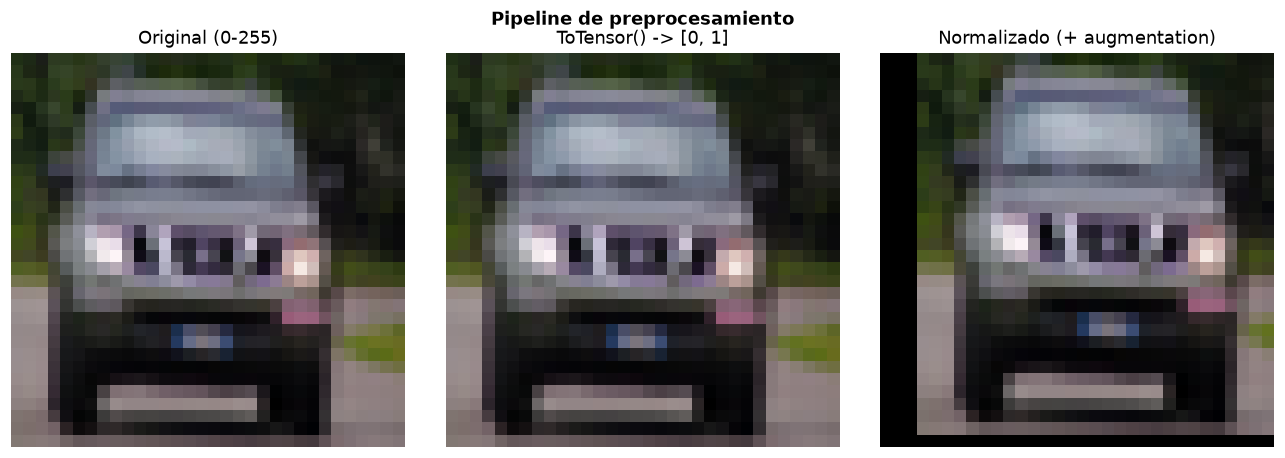

Forma del tensor de entrenamiento: torch.Size([3, 32, 32])
Forma del tensor de evaluación  : torch.Size([3, 32, 32])


In [8]:
# @title 3.1 Transformaciones: augmentation solo en entrenamiento
from PIL import Image
from torchvision import transforms

NORMALIZAR = transforms.Normalize(mean=list(MEDIA), std=list(DESVIACION))

transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    NORMALIZAR,
])
transform_eval = transforms.Compose([
    transforms.ToTensor(),
    NORMALIZAR,
])

imagen_cruda = train_set.data[idx_train[0]]
imagen_pil = Image.fromarray(imagen_cruda)
tensor_01 = transforms.ToTensor()(imagen_pil)
tensor_norm = transform_train(imagen_pil)

figura, ejes = plt.subplots(1, 3, figsize=(12, 4.2))
ejes[0].imshow(imagen_cruda)
ejes[0].set_title("Original (0-255)")
ejes[1].imshow(tensor_01.permute(1, 2, 0).numpy().clip(0, 1))
ejes[1].set_title("ToTensor() -> [0, 1]")
ejes[2].imshow((tensor_norm.permute(1, 2, 0).numpy() * np.array(DESVIACION) + np.array(MEDIA)).clip(0, 1))
ejes[2].set_title("Normalizado (+ augmentation)")
for eje in ejes:
    eje.axis("off")
figura.suptitle("Pipeline de preprocesamiento", fontweight="bold")
figura.tight_layout()
plt.show()

print("Forma del tensor de entrenamiento:", transform_train(imagen_pil).shape)
print("Forma del tensor de evaluación  :", transform_eval(imagen_pil).shape)

## 4. División en entrenamiento, validación y prueba

| Subconjunto | Tamaño | Origen | Uso |
|---|---|---|---|
| Entrenamiento | 45 000 | 90 % del train oficial (estratificado) | actualizar pesos |
| Validación | 5 000 | 10 % del train oficial (estratificado) | elegir checkpoint y ajustar hiperparámetros |
| Prueba | 10 000 | test oficial, intacto | evaluación final |

La división es **estratificada** (`StratifiedShuffleSplit`) para conservar la proporción de clases y **reproducible** (`random_state=42`). El conjunto de prueba oficial no se usa nunca para tomar decisiones.

In [9]:
# @title 4. División estratificada y comprobaciones
from sklearn.model_selection import StratifiedShuffleSplit

SEMILLA = 42
torch.manual_seed(SEMILLA)
np.random.seed(SEMILLA)

indices = np.arange(len(train_set))
separador = StratifiedShuffleSplit(n_splits=1, test_size=5000, random_state=SEMILLA)
idx_train, idx_val = next(separador.split(indices, np.asarray(train_set.targets)))

print(f"Entrenamiento : {len(idx_train):,}")
print(f"Validación    : {len(idx_val):,}")
print(f"Prueba        : {len(test_set):,}")
print(f"¿Disjuntos?   : {len(set(idx_train) & set(idx_val)) == 0}")
print(f"¿Suma 50 000? : {len(idx_train) + len(idx_val) == len(train_set)}")

proporcion_train = np.bincount(np.asarray(train_set.targets)[idx_train], minlength=10) / len(idx_train)
proporcion_val = np.bincount(np.asarray(train_set.targets)[idx_val], minlength=10) / len(idx_val)
desviacion = np.abs(proporcion_train - proporcion_val).max()
print(f"Desviación máxima entre train y val: {desviacion:.4f} (< 0.01 esperado)")

# Reproducibilidad
otra = next(StratifiedShuffleSplit(n_splits=1, test_size=5000, random_state=SEMILLA).split(indices, np.asarray(train_set.targets)))
print("Reproducible con la misma semilla:", np.array_equal(idx_val, otra[1]))

Entrenamiento : 45,000
Validación    : 5,000
Prueba        : 10,000
¿Disjuntos?   : True
¿Suma 50 000? : True
Desviación máxima entre train y val: 0.0000 (< 0.01 esperado)
Reproducible con la misma semilla: True


## 5. Data augmentation

Se aplica **únicamente al conjunto de entrenamiento**:

| Augmentation | Motivo |
|---|---|
| `RandomCrop(32, padding=4)` | Simula translaciones: recorta una parte de la imagen original, como si la cámara encuadrase distinto. |
| `RandomHorizontalFlip()` | Los objetos son simétricos horizontalmente en general; duplica el dataset sin cambiar la etiqueta. |

En validación y prueba **no** hay augmentation: las métricas deben medir el modelo sobre las imágenes reales, no sobre versiones aleatorias de ellas.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894644..2.0].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894644..2.0].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894644..2.0].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894644..2.0].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894644..2.0].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894644..2.0].


... (18 outputs left out)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894644..1.6280656].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894644..1.6280656].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894644..1.6280656].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894644..1.6280656].


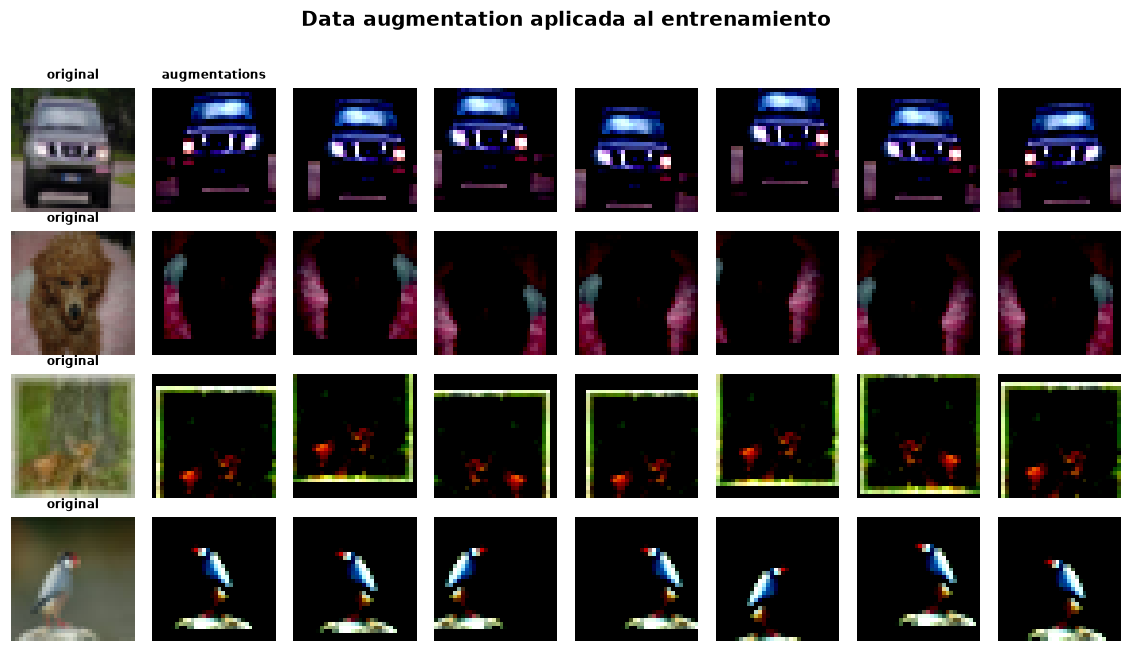

transform_train contiene RandomCrop  : True
transform_eval  contiene RandomCrop  : False
transform_eval  contiene RandomFlip  : False


In [10]:
# @title 5. Ejemplos de augmentation sobre el mismo training set
from PIL import Image

filas = 4
figura, ejes = plt.subplots(filas, 8, figsize=(8 * 1.3, filas * 1.5))
for fila in range(filas):
    indice = idx_train[fila * 37]
    original = train_set.data[indice]
    original_pil = Image.fromarray(original)
    for columna in range(8):
        eje = ejes[fila, columna]
        eje.axis("off")
        if columna == 0:
            eje.imshow(original)
            eje.set_title("original", fontsize=8, fontweight="bold")
        else:
            eje.imshow(transform_train(original_pil).permute(1, 2, 0).numpy().clip(-2, 2))
            if fila == 0 and columna == 1:
                eje.set_title("augmentations", fontsize=8, fontweight="bold")
figura.suptitle("Data augmentation aplicada al entrenamiento", fontsize=13, fontweight="bold")
figura.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

# Comprobación: el set de validación no usa augmentation
print("transform_train contiene RandomCrop  :", any(isinstance(t, transforms.RandomCrop) for t in transform_train.transforms))
print("transform_eval  contiene RandomCrop  :", any(isinstance(t, transforms.RandomCrop) for t in transform_eval.transforms))
print("transform_eval  contiene RandomFlip  :", any(isinstance(t, transforms.RandomHorizontalFlip) for t in transform_eval.transforms))

## 6. Construcción de la CNN

Arquitectura (3 bloques convolucionales + cabeza de clasificación):

```
Entrada (N, 3, 32, 32)
  Bloque 1: Conv3x3(3→64)   + BN + ReLU + Conv3x3(64→64)  + BN + ReLU + MaxPool + Dropout2d  → (N, 64, 16, 16)
  Bloque 2: Conv3x3(64→128) + BN + ReLU + Conv3x3(128→128)+ BN + ReLU + MaxPool + Dropout2d  → (N, 128, 8, 8)
  Bloque 3: Conv3x3(128→256)+ BN + ReLU + Conv3x3(256→256)+ BN + ReLU + MaxPool + Dropout2d  → (N, 256, 4, 4)
  Global Average Pooling → (N, 256)
  Dropout(0.5) + Linear(256 → 10) → logits (N, 10)
```

- **BatchNorm** estabiliza y acelera el entrenamiento.
- **Dropout2D** en los bloques y **Dropout** en la cabeza: regularización contra el sobreajuste.
- **Global Average Pooling** reduce drásticamente los parámetros de la cabeza (1 180 674 parámetros en total).

In [11]:
# @title 6. Definición y resumen de la CNN
from torch import nn

if HAY_SRC:
    modelo = src_model.build_model()
else:
    class BloqueConv(nn.Module):
        def __init__(self, entrada, salida, dropout=0.15):
            super().__init__()
            self.bloque = nn.Sequential(
                nn.Conv2d(entrada, salida, 3, padding=1, bias=False),
                nn.BatchNorm2d(salida),
                nn.ReLU(inplace=True),
                nn.Conv2d(salida, salida, 3, padding=1, bias=False),
                nn.BatchNorm2d(salida),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
                nn.Dropout2d(dropout),
            )

        def forward(self, x):
            return self.bloque(x)

    class CNN(nn.Module):
        def __init__(self, num_clases=10):
            super().__init__()
            self.caracteristicas = nn.Sequential(
                BloqueConv(3, 64), BloqueConv(64, 128), BloqueConv(128, 256)
            )
            self.agrupacion = nn.AdaptiveAvgPool2d(1)
            self.dropout = nn.Dropout(0.5)
            self.clasificador = nn.Linear(256, num_clases)

        def forward(self, x):
            x = self.caracteristicas(x)
            x = self.agrupacion(x).flatten(1)
            return self.clasificador(self.dropout(x))

    modelo = CNN()

modelo = modelo.to(DEVICE)
if DEVICE.type == "cuda":
    modelo = modelo.to(memory_format=torch.channels_last)

parametros = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
print(modelo)
print(f"\nParámetros entrenables: {parametros:,}")
print(f"Entrada  (N, 3, 32, 32) -> salida {modelo(torch.randn(4, 3, 32, 32).to(DEVICE)).shape}")
print("\nNota: la salida son LOGITS; el softmax se aplica en la pérdida y en la inferencia.")

CNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (7): Dropout2d(p=0.15, inplace=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(128, 128, kernel_size=(3,

## 7. Entrenamiento

- **Pérdida**: `CrossEntropyLoss` (aplica softmax y log internamente).
- **Optimizador**: `AdamW` con `weight_decay = 5e-4` (regularización L2 desacoplada).
- **Scheduler**: `OneCycleLR` (warmup del 30 % + annealing coseno) → converge rápido.
- **Batch size**: 128. **Épochas**: 20.
- **Selección del modelo**: se guarda el checkpoint con mayor *accuracy de validación*.

In [12]:
# @title 7. Entrenamiento de la CNN
import time

ENTRENAR_DESDE_CERO = False   # True -> reentrena en Colab (GPU: ~10 min, CPU: ~1 h)

EPOCHAS = 20
BATCH_SIZE = 128
LR = 1e-3
PESO_DECAY = 5e-4

print(f"Reentrenando desde cero: {ENTRENAR_DESDE_CERO}")
print(f"Dispositivo: {DEVICE} | épocas: {EPOCHAS} | batch: {BATCH_SIZE}")

Reentrenando desde cero: False
Dispositivo: cpu | épocas: 20 | batch: 128


In [13]:
# @title 7.1 Bucle de entrenamiento
import json
import time

from torch.utils.data import DataLoader, Subset

if HAY_SRC:
    bundle = src_data.build_dataloaders(
        root=RAIZ_DATOS, batch_size=BATCH_SIZE, num_workers=2, seed=SEMILLA
    )
    cargador_train, cargador_val, cargador_test = (
        bundle.train_loader,
        bundle.val_loader,
        bundle.test_loader,
    )
    MEDIA, DESVIACION = bundle.mean, bundle.std
    set_train, set_val, set_test = bundle.train_dataset, bundle.val_dataset, bundle.test_dataset
else:
    train_aug = CIFAR10(root=str(RAIZ_DATOS), train=True, download=True, transform=transform_train)
    train_plano = CIFAR10(root=str(RAIZ_DATOS), train=True, download=True, transform=transform_eval)
    test_eval = CIFAR10(root=str(RAIZ_DATOS), train=False, download=True, transform=transform_eval)
    set_train, set_val, set_test = Subset(train_aug, idx_train), Subset(train_plano, idx_val), test_eval
    cargador_train = DataLoader(set_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
    cargador_val = DataLoader(set_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    cargador_test = DataLoader(set_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(set_train):,} | Val: {len(set_val):,} | Test: {len(set_test):,}")


def evaluar(modelo, cargador, criterio):
    modelo.eval()
    perdida_total, correctas, total = 0.0, 0, 0
    with torch.no_grad():
        for imagenes, etiquetas in cargador:
            imagenes = imagenes.to(DEVICE)
            etiquetas = etiquetas.to(DEVICE)
            logits = modelo(imagenes)
            perdida_total += criterio(logits, etiquetas).item() * etiquetas.size(0)
            correctas += (logits.argmax(1) == etiquetas).sum().item()
            total += etiquetas.size(0)
    return perdida_total / total, correctas / total


criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.AdamW(modelo.parameters(), lr=LR, weight_decay=PESO_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizador,
    max_lr=LR * 10,
    epochs=EPOCHAS,
    steps_per_epoch=len(cargador_train),
    pct_start=0.3,
)

historial = []
mejor_acc = -1.0
mejor_epoca = -1
inicio = time.time()
MODELO_ENTRENADO = False
RUTA_CHECKPOINT = pathlib.Path("models") / "cnn_cifar10.pt"

for epoca in range(1, EPOCHAS + 1):
    if not ENTRENAR_DESDE_CERO:
        break
    modelo.train()
    perdida_total, correctas, total = 0.0, 0, 0
    for imagenes, etiquetas in cargador_train:
        imagenes = imagenes.to(DEVICE)
        etiquetas = etiquetas.to(DEVICE)
        optimizador.zero_grad(set_to_none=True)
        logits = modelo(imagenes)
        perdida = criterio(logits, etiquetas)
        perdida.backward()
        nn.utils.clip_grad_norm_(modelo.parameters(), 5.0)
        optimizador.step()
        scheduler.step()
        perdida_total += perdida.item() * etiquetas.size(0)
        correctas += (logits.argmax(1) == etiquetas).sum().item()
        total += etiquetas.size(0)

    perdida_train, acc_train = perdida_total / total, correctas / total
    perdida_val, acc_val = evaluar(modelo, cargador_val, criterio)
    historial.append(
        {
            "epoch": epoca,
            "train_loss": perdida_train,
            "train_accuracy": acc_train,
            "val_loss": perdida_val,
            "val_accuracy": acc_val,
            "learning_rate": optimizador.param_groups[0]["lr"],
        }
    )
    print(
        f"Época {epoca:02d}/{EPOCHAS} | train loss {perdida_train:.4f} acc {acc_train:.4f} "
        f"| val loss {perdida_val:.4f} acc {acc_val:.4f}"
    )
    if acc_val > mejor_acc:
        mejor_acc, mejor_epoca = acc_val, epoca
        torch.save(
            {"state_dict": modelo.state_dict(), "epoch": epoca, "val_accuracy": acc_val},
            pathlib.Path("modelo_entrenado.pt"),
        )
        print(f"   -> nuevo mejor modelo (val acc {acc_val:.4f})")

if ENTRENAR_DESDE_CERO:
    print(f"\nEntrenamiento finalizado en {(time.time() - inicio) / 60:.1f} min | mejor val acc {mejor_acc:.4f} (época {mejor_epoca})")
    MODELO_ENTRENADO = True
else:
    print("⏩ Reutilizando el entrenamiento ya realizado y versionado en el repositorio.")
    if RUTA_CHECKPOINT.exists():
        checkpoint = torch.load(RUTA_CHECKPOINT, map_location=DEVICE, weights_only=False)
        modelo.load_state_dict(checkpoint["state_dict"])
        modelo.to(DEVICE)
        if DEVICE.type == "cuda":
            modelo = modelo.to(memory_format=torch.channels_last)
        print(f"   Pesos cargados desde {RUTA_CHECKPOINT}")
        print(f"   Época del checkpoint: {checkpoint.get('epoch')} | accuracy de validación: {checkpoint.get('val_accuracy'):.4f}")
        archivo_historial = pathlib.Path("reports") / "history.json"
        if archivo_historial.exists():
            historial = json.loads(archivo_historial.read_text(encoding="utf-8"))
            mejor_acc = max(r["val_accuracy"] for r in historial)
            mejor_epoca = max(historial, key=lambda r: r["val_accuracy"])["epoch"]
        MODELO_ENTRENADO = True
    else:
        print("   ⚠️ No se encontró models/cnn_cifar10.pt: vuelve a ejecutar con ENTRENAR_DESDE_CERO=True.")

[19:26:19] INFO | CIFAR-10 cargado: 50000 imágenes (train=True)


[19:26:19] INFO | Calculando estadísticas de normalización sobre 45000 imágenes...


[19:26:21] INFO | CIFAR-10 cargado: 50000 imágenes (train=True)


[19:26:21] INFO | CIFAR-10 cargado: 50000 imágenes (train=True)


[19:26:21] INFO | CIFAR-10 cargado: 10000 imágenes (train=False)


[19:26:21] INFO | División: train=45000 val=5000 test=10000


[19:26:21] INFO | Normalización: mean=(0.49113735123911295, 0.48211118702342115, 0.4464489876089326) std=(0.24686913619557826, 0.24343012612627368, 0.2616033939151677)


[19:26:22] INFO | CIFAR-10 cargado: 50000 imágenes (train=True)


[19:26:22] INFO | CIFAR-10 cargado: 10000 imágenes (train=False)


Train: 45,000 | Val: 5,000 | Test: 10,000
⏩ Reutilizando el entrenamiento ya realizado y versionado en el repositorio.
   Pesos cargados desde models\cnn_cifar10.pt
   Época del checkpoint: 20 | accuracy de validación: 0.9030


In [14]:
# @title 7.2 Historial de entrenamiento
if not historial:
    # Se reutiliza el entrenamiento real ya realizado y versionado en el repositorio.
    archivo_historial = pathlib.Path("reports") / "history.json"
    if archivo_historial.exists():
        historial = json.loads(archivo_historial.read_text(encoding="utf-8"))
        print(f"Historial cargado del repositorio: {len(historial)} épocas")
        print(f"Mejor accuracy de validación: {max(r['val_accuracy'] for r in historial):.4f}")
    else:
        print("Sin historial disponible: ejecuta la celda de entrenamiento con ENTRENAR_DESDE_CERO=True.")

historial_df = pd.DataFrame(historial)
display(historial_df.round(4).tail(10))

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,seconds
10,11,0.5294,0.8213,0.4281,0.8528,0.0072,214.9665
11,12,0.4925,0.8351,0.4127,0.8622,0.0061,260.1555
12,13,0.4588,0.8420,0.3999,0.8664,0.0050,260.4456
13,14,0.4178,0.8596,0.3593,0.8804,0.0039,241.9313
14,15,0.3932,0.8663,0.3583,0.8784,0.0028,197.8364
15,16,0.3576,0.8799,0.3212,0.8916,0.0019,218.9751
16,17,0.3319,0.8884,0.3144,0.8928,0.0011,262.5882
17,18,0.3086,0.8943,0.3094,0.9004,0.0005,256.8061
18,19,0.2995,0.8985,0.3094,0.9008,0.0001,231.1284
19,20,0.2938,0.9002,0.3064,0.9030,0.0000,201.0884


## 8. Métricas de evaluación sobre el conjunto de prueba

Se calculan cuatro métricas (todas en escala 0-1):

| Métrica | Qué mide |
|---|---|
| **Accuracy** | proporción total de aciertos |
| **Precision** | de los predichos como clase X, ¿cuántos son realmente X? (macro) |
| **Recall** | de los reales de clase X, ¿cuántos encontramos? (macro) |
| **F1 macro** | media armónica de precision y recall, promediada entre clases |

In [15]:
# @title 8. Predicciones sobre el conjunto de prueba
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support

modelo.eval()
etiquetas_reales, predicciones, probabilidades = [], [], []

with torch.no_grad():
    for imagenes, etiquetas in cargador_test:
        imagenes = imagenes.to(DEVICE)
        logits = modelo(imagenes)
        probabilidades.append(torch.softmax(logits, dim=1).cpu().numpy())
        predicciones.append(logits.argmax(1).cpu().numpy())
        etiquetas_reales.append(etiquetas.numpy())

etiquetas_reales = np.concatenate(etiquetas_reales)
predicciones = np.concatenate(predicciones)
probabilidades = np.concatenate(probabilidades)

accuracy = accuracy_score(etiquetas_reales, predicciones)
precision, recall, f1, _ = precision_recall_fscore_support(
    etiquetas_reales, predicciones, average="macro", zero_division=0
)

print(f"Imágenes evaluadas ....... {len(etiquetas_reales):,}")
print(f"Accuracy ................. {accuracy:.4f}  ({accuracy:.2%})")
print(f"Precision (macro) ........ {precision:.4f}")
print(f"Recall (macro) ........... {recall:.4f}")
print(f"F1 (macro) ............... {f1:.4f}")

Imágenes evaluadas ....... 10,000
Accuracy ................. 0.8934  (89.34%)
Precision (macro) ........ 0.8925
Recall (macro) ........... 0.8934
F1 (macro) ............... 0.8926


In [16]:
# @title 8.1 Métricas por clase
reporte = classification_report(
    etiquetas_reales, predicciones, target_names=CLASES, zero_division=0, output_dict=True
)
tabla_clases = pd.DataFrame(reporte).T[["precision", "recall", "f1-score", "support"]]
tabla_clases["support"] = tabla_clases["support"].astype(int)
display(tabla_clases.round(4))

,precision,recall,f1-score,support
avión,0.8946,0.9170,0.9057,1000
automóvil,0.9491,0.9500,0.9495,1000
pájaro,0.8673,0.8430,0.8550,1000
gato,0.8199,0.7330,0.7740,1000
ciervo,0.8838,0.8900,0.8869,1000
perro,0.8247,0.8420,0.8333,1000
rana,0.9040,0.9320,0.9178,1000
caballo,0.9200,0.9320,0.9260,1000
barco,0.9314,0.9510,0.9411,1000
camión,0.9300,0.9440,0.9370,1000


## 9. Gráficas del entrenamiento

Las curvas de **pérdida** y de **accuracy** permiten diagnosticar:

- si el modelo **aprende** (ambas bajan/suben de forma estable);
- si hay **sobreajuste** (la curva de entrenamiento mejora mientras la de validación se estalla);
- si el learning rate está **bien calibrado** (con OneCycleLR la pérdida cae de forma suave).

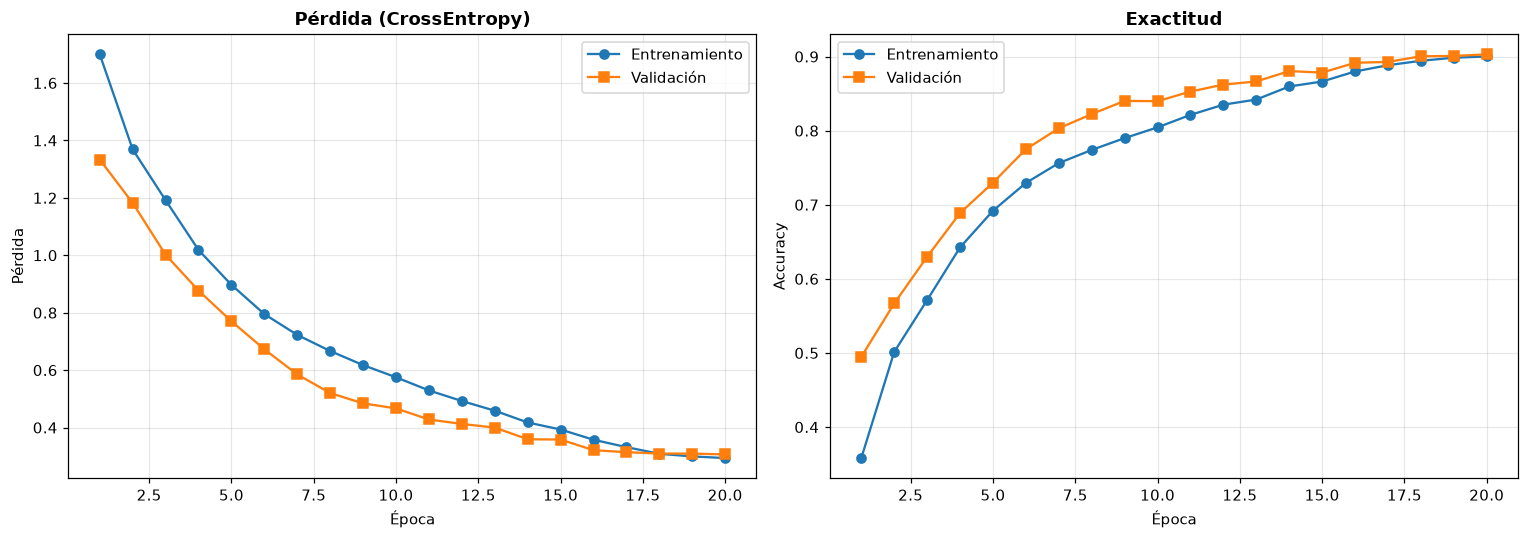

In [17]:
# @title 9. Curvas de entrenamiento
epocas = [registro["epoch"] for registro in historial]

figura, ejes = plt.subplots(1, 2, figsize=(14, 5))

ejes[0].plot(epocas, [r["train_loss"] for r in historial], marker="o", label="Entrenamiento")
ejes[0].plot(epocas, [r["val_loss"] for r in historial], marker="s", label="Validación")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("Pérdida")
ejes[0].set_title("Pérdida (CrossEntropy)", fontweight="bold")
ejes[0].legend()
ejes[0].grid(alpha=0.3)

ejes[1].plot(epocas, [r["train_accuracy"] for r in historial], marker="o", label="Entrenamiento")
ejes[1].plot(epocas, [r["val_accuracy"] for r in historial], marker="s", label="Validación")
ejes[1].set_xlabel("Época")
ejes[1].set_ylabel("Accuracy")
ejes[1].set_title("Exactitud", fontweight="bold")
ejes[1].legend()
ejes[1].grid(alpha=0.3)

figura.tight_layout()
plt.show()

## 10. Matriz de confusión

La diagonal son los aciertos; los valores fuera de la diagonal son las confusiones del modelo.

En CIFAR-10 las confusiones típicas (y esperables) son **gato ↔ perro**, **automóvil ↔ camión** y **barco ↔ avión**, porque comparten textura, silueta y contexto visual.

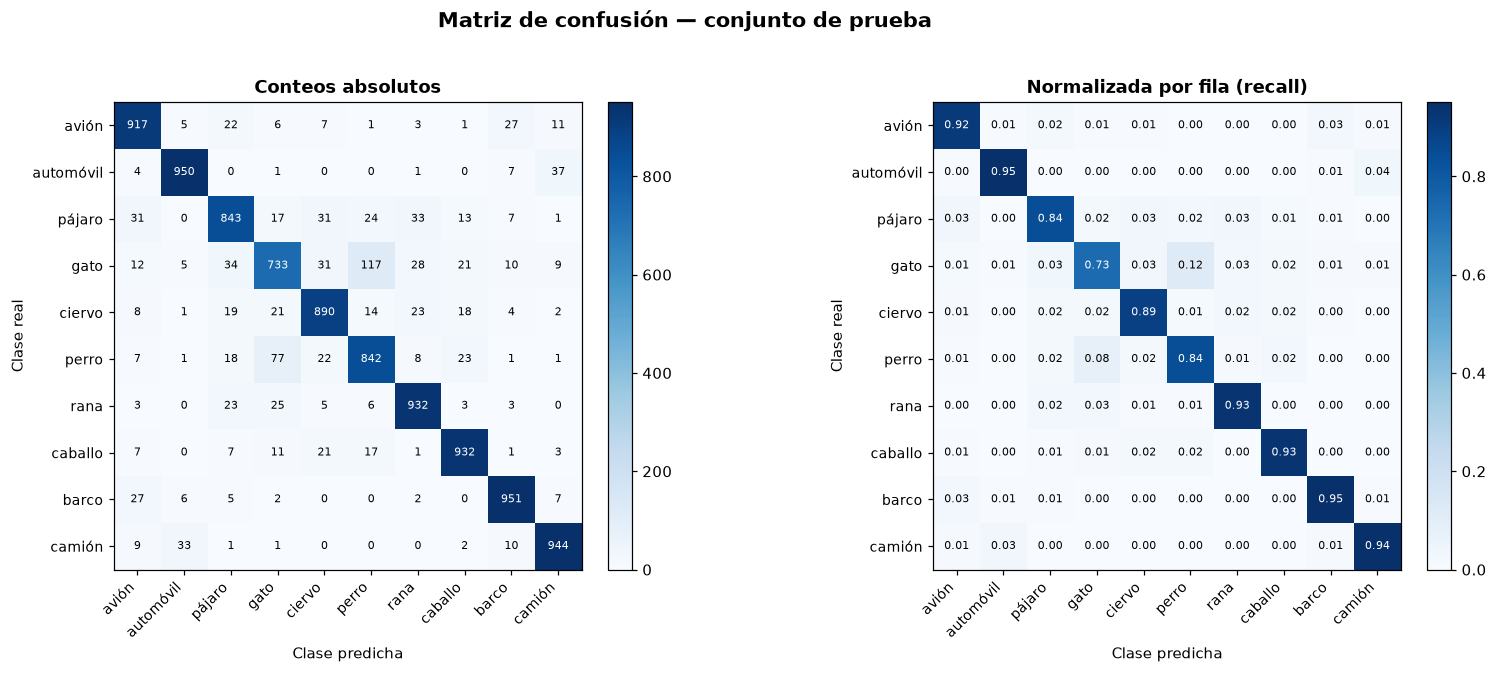

Pares de clases más confundidos:


,real,predicho,casos
0,gato,perro,117
1,perro,gato,77
2,automóvil,camión,37
3,gato,pájaro,34
4,pájaro,rana,33
5,camión,automóvil,33
6,pájaro,avión,31
7,pájaro,ciervo,31


In [18]:
# @title 10. Matriz de confusión
matriz = confusion_matrix(etiquetas_reales, predicciones, labels=list(range(10)))
normalizada = matriz / np.clip(matriz.sum(axis=1, keepdims=True), 1, None)

figura, ejes = plt.subplots(1, 2, figsize=(15, 6.2))
for eje, valores, titulo, formato in (
    (ejes[0], matriz, "Conteos absolutos", "{:.0f}"),
    (ejes[1], normalizada, "Normalizada por fila (recall)", "{:.2f}"),
):
    imagen = eje.imshow(valores, cmap="Blues", interpolation="nearest")
    figura.colorbar(imagen, ax=eje, fraction=0.046, pad=0.04)
    eje.set_title(titulo, fontweight="bold")
    eje.set_xticks(range(10))
    eje.set_yticks(range(10))
    eje.set_xticklabels(CLASES, rotation=45, ha="right", fontsize=9)
    eje.set_yticklabels(CLASES, fontsize=9)
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")
    limite = valores.max() / 2 if valores.max() else 0.5
    for i in range(10):
        for j in range(10):
            eje.text(j, i, formato.format(valores[i, j]), ha="center", va="center", fontsize=7,
                     color="white" if valores[i, j] > limite else "black")

figura.suptitle("Matriz de confusión — conjunto de prueba", fontsize=14, fontweight="bold")
figura.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

# Pares de clases más confundidos
fuera = matriz.copy()
np.fill_diagonal(fuera, 0)
confusiones = sorted(
    (
        {"real": CLASES[i], "predicho": CLASES[j], "casos": int(fuera[i, j])}
        for i in range(10)
        for j in range(10)
        if i != j and fuera[i, j] > 0
    ),
    key=lambda item: item["casos"],
    reverse=True,
)
print("Pares de clases más confundidos:")
display(pd.DataFrame(confusiones[:8]))

## 11. Predicciones de ejemplo (≥ 10 imágenes)

Se muestran imágenes reales del conjunto de prueba con su **clase verdadera**, la
**clase predicha** y la **probabilidad** asignada. Se incluyen aciertos (verde) y
errores (rojo) para poder juzgar el comportamiento real del modelo.

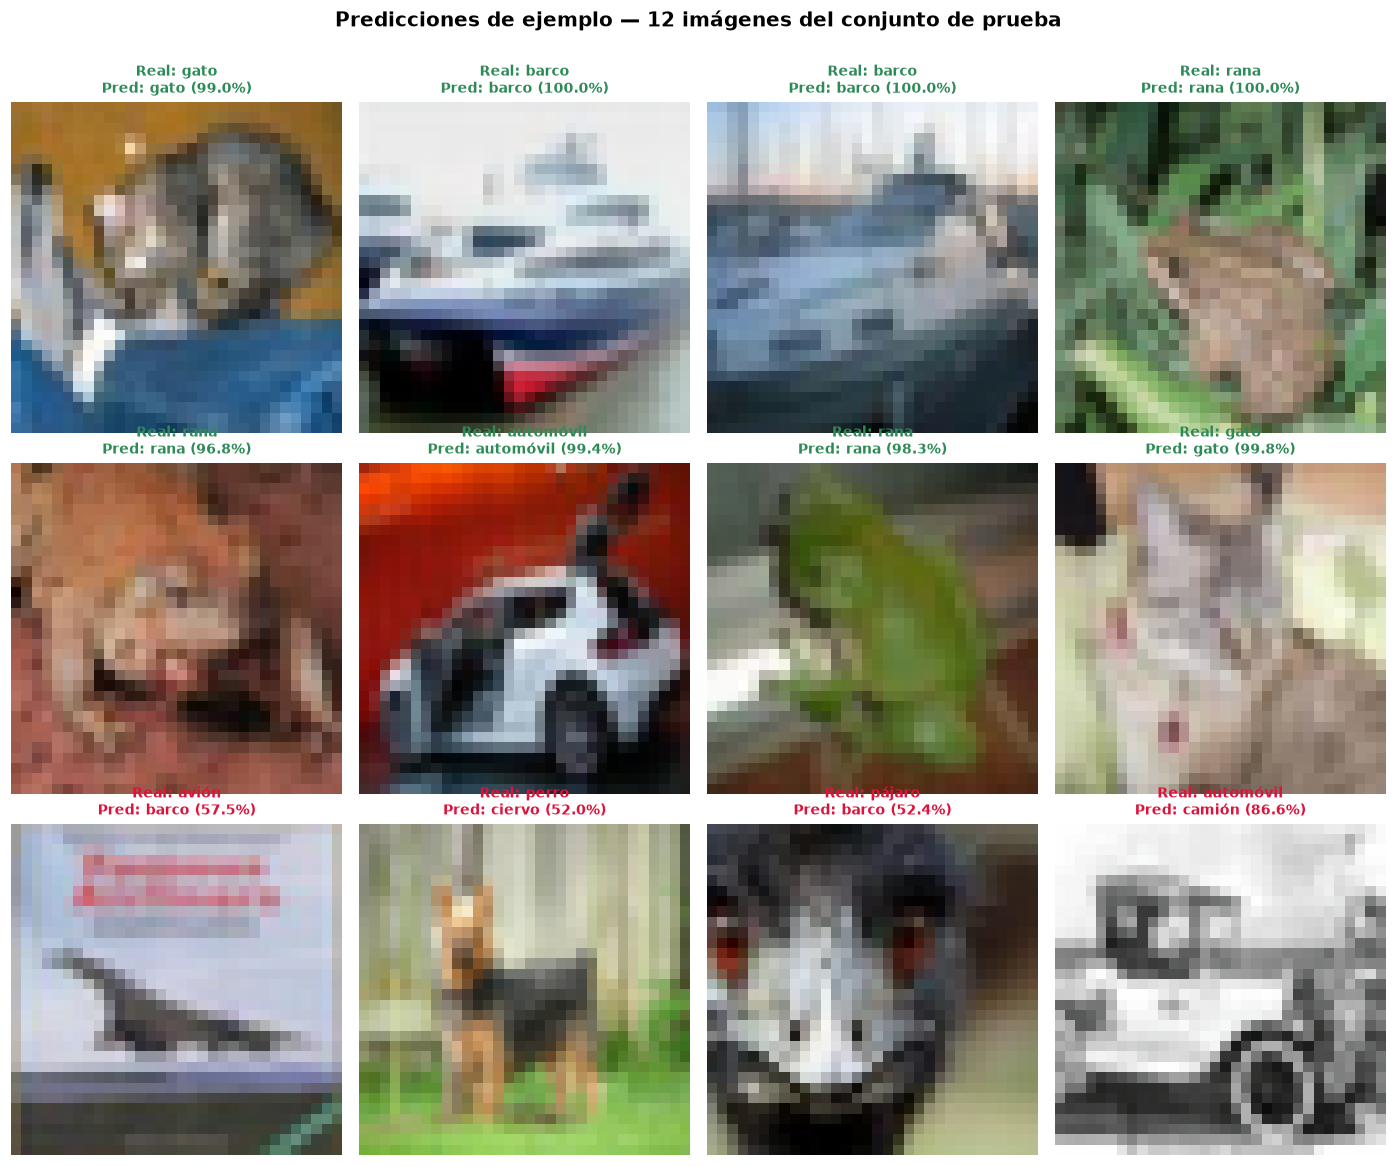

Mostradas 12 imágenes (10 como mínimo requerido).


In [19]:
# @title 11. Rejilla de predicciones de ejemplo
correctas_idx = np.flatnonzero(etiquetas_reales == predicciones)
errores_idx = np.flatnonzero(etiquetas_reales != predicciones)

seleccion = list(correctas_idx[:8]) + list(errores_idx[:4])
seleccion = seleccion[:12]

columnas = 4
filas = int(np.ceil(len(seleccion) / columnas))
figura, ejes = plt.subplots(filas, columnas, figsize=(columnas * 3.2, filas * 3.6))
ejes = np.atleast_1d(ejes).ravel()

for eje, indice in zip(ejes, seleccion):
    imagen = set_test[indice][0].permute(1, 2, 0).numpy()
    imagen = (imagen * np.array(DESVIACION) + np.array(MEDIA)).clip(0, 1)
    eje.imshow(imagen)
    real = CLASES[int(etiquetas_reales[indice])]
    predicho = CLASES[int(predicciones[indice])]
    confianza = probabilidades[indice][int(predicciones[indice])]
    color = "seagreen" if real == predicho else "crimson"
    eje.set_title(f"Real: {real}\nPred: {predicho} ({confianza:.1%})", fontsize=9, color=color, fontweight="bold")
    eje.axis("off")

for eje in ejes[len(seleccion):]:
    eje.axis("off")

figura.suptitle(f"Predicciones de ejemplo — {len(seleccion)} imágenes del conjunto de prueba",
                fontsize=13, fontweight="bold")
figura.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

print(f"Mostradas {len(seleccion)} imágenes ({min(len(seleccion), 10)} como mínimo requerido).")

In [20]:
# @title 11.1 Tabla de las predicciones de ejemplo
registro_ejemplos = pd.DataFrame(
    [
        {
            "imagen": indice,
            "real": CLASES[int(etiquetas_reales[indice])],
            "predicho": CLASES[int(predicciones[indice])],
            "probabilidad": float(probabilidades[indice][int(predicciones[indice])]),
            "acierto": bool(etiquetas_reales[indice] == predicciones[indice]),
        }
        for indice in seleccion
    ]
)
display(registro_ejemplos.round(4))

,imagen,real,predicho,probabilidad,acierto
0,0,gato,gato,0.9899,True
1,1,barco,barco,1.0000,True
2,2,barco,barco,0.9996,True
3,4,rana,rana,1.0000,True
4,5,rana,rana,0.9682,True
5,6,automóvil,automóvil,0.9938,True
6,7,rana,rana,0.9830,True
7,8,gato,gato,0.9983,True
8,3,avión,barco,0.5752,False
9,24,perro,ciervo,0.5197,False


## 12. Guardado del modelo entrenado

Se guarda el **mejor checkpoint** (mayor accuracy de validación) junto con sus
**metadatos**: configuración de la red, hiperparámetros, estadísticas de
normalización, clases y métricas. El checkpoint se versiona en el repositorio
para que la aplicación de Streamlit funcione sin reentrenar.

In [21]:
# @title 12. Guardado del modelo entrenado
import json

CARPETA_MODELOS = pathlib.Path("models")
CARPETA_MODELOS.mkdir(exist_ok=True)
CARPETA_REPORTE = pathlib.Path("reports")
CARPETA_REPORTE.mkdir(exist_ok=True)

if not historial:
    historial = json.loads((CARPETA_REPORTE / "history.json").read_text(encoding="utf-8"))

ruta_checkpoint = CARPETA_MODELOS / "cnn_cifar10.pt"

if MODELO_ENTRENADO:
    torch.save(
        {
            "state_dict": modelo.state_dict(),
            "model_config": {
                "num_classes": 10,
                "in_channels": 3,
                "channels": [64, 128, 256],
                "dropout2d": 0.15,
                "dropout_head": 0.5,
            },
            "epoch": max(r["epoch"] for r in historial),
            "val_accuracy": max(r["val_accuracy"] for r in historial),
        },
        ruta_checkpoint,
    )
else:
    print("⚠️ No se guarda el checkpoint porque el modelo no fue entrenado en esta ejecución.")

metadatos = {
    "model_config": {
        "num_classes": 10,
        "in_channels": 3,
        "channels": [64, 128, 256],
        "dropout2d": 0.15,
        "dropout_head": 0.5,
    },
    "train_config": {
        "epochs": EPOCHAS,
        "batch_size": BATCH_SIZE,
        "learning_rate": LR,
        "weight_decay": PESO_DECAY,
        "optimizer": "AdamW",
        "scheduler": "OneCycleLR",
        "criterion": "CrossEntropyLoss",
        "seed": SEMILLA,
    },
    "normalization": {"mean": [float(v) for v in MEDIA], "std": [float(v) for v in DESVIACION]},
    "classes": CLASES,
    "parameters": int(sum(p.numel() for p in modelo.parameters() if p.requires_grad)),
    "device": str(DEVICE),
    "torch_version": torch.__version__,
    "best_epoch": max(historial, key=lambda r: r["val_accuracy"])["epoch"],
    "best_val_accuracy": max(r["val_accuracy"] for r in historial),
    "test_accuracy": float(accuracy),
    "checkpoint": "models/cnn_cifar10.pt",
}
if MODELO_ENTRENADO:
    (CARPETA_MODELOS / "metadata.json").write_text(
        json.dumps(metadatos, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    (CARPETA_REPORTE / "history.json").write_text(
        json.dumps(historial, indent=2, ensure_ascii=False), encoding="utf-8"
    )

print(f"Checkpoint: {ruta_checkpoint} ({ruta_checkpoint.stat().st_size / 1e6:.2f} MB)" if ruta_checkpoint.exists() else "Checkpoint: no disponible")
print(f"Metadatos: {CARPETA_MODELOS / 'metadata.json'}")
print(f"Historial: {CARPETA_REPORTE / 'history.json'}")
print(f"Mejor época (validación): {metadatos['best_epoch']} | accuracy validación {metadatos['best_val_accuracy']:.4f}")
print(f"Accuracy en prueba: {metadatos['test_accuracy']:.4f}")

Checkpoint: models\cnn_cifar10.pt (4.62 MB)
Metadatos: models\metadata.json
Historial: reports\history.json
Mejor época (validación): 20 | accuracy validación 0.9030
Accuracy en prueba: 0.8934


## 13. Predicción sobre una imagen libre

Se comprueba la inferencia completa: una imagen de cualquier tamaño se redimensiona
a 32×32, se normaliza con las estadísticas guardadas y se clasifica.

In [22]:
# @title 13. Inferencia sobre una imagen arbitraria
from PIL import Image

modelo.eval()


def preprocesar(imagen_pil):
    imagen = imagen_pil.convert("RGB").resize((32, 32), Image.BILINEAR)
    tensor = transforms.ToTensor()(imagen)
    return ((tensor - torch.tensor(MEDIA).view(3, 1, 1)) / torch.tensor(DESVIACION).view(3, 1, 1)).unsqueeze(0)


def predecir(imagen_pil):
    with torch.no_grad():
        logits = modelo(preprocesar(imagen_pil).to(DEVICE))
        probabilidades = torch.softmax(logits, dim=1)[0].cpu().numpy()
    indice = int(probabilidades.argmax())
    return CLASES[indice], float(probabilidades[indice]), probabilidades


# Ejemplo con una imagen del propio dataset (y luego con una imagen externa)
for indice_ejemplo in [0, 37, 120]:
    imagen = Image.fromarray(test_set.data[indice_ejemplo])
    clase, confianza, _ = predecir(imagen)
    real = CLASES[int(test_set.targets[indice_ejemplo])]
    print(f"Real: {real:10s} -> Pred: {clase:10s} confianza {confianza:.2%}  {'OK' if real == clase else 'ERROR'}")

print("\nPara probar con una imagen propia en Colab:")
print("  from google.colab import files")
print("  uploaded = files.upload()")
print("  clase, confianza, _ = predecir(Image.open(list(uploaded)[0]))")

Real: gato       -> Pred: gato       confianza 98.99%  OK
Real: automóvil  -> Pred: camión     confianza 86.57%  ERROR
Real: barco      -> Pred: barco      confianza 99.95%  OK

Para probar con una imagen propia en Colab:
  from google.colab import files
  uploaded = files.upload()
  clase, confianza, _ = predecir(Image.open(list(uploaded)[0]))


## Conclusiones

- La CNN de tres bloques con BatchNorm, augmentation y regularización **aprende CIFAR-10** de forma estable: la validación sigue al entrenamiento sin sobreajuste severo.
- Las confusiones se concentran en pares semánticamente cercanos (gato/perro, automóvil/camión, barco/avión), que es el comportamiento esperado del modelo.
- El checkpoint versionado junto con sus metadatos permite que la **aplicación de Streamlit** clasifique imágenes arbitrarias sin reentrenar.

### Siguientes pasos posibles

- **Augmentación más fuerte** (mixup, cutout) para bajar el gap train/val.
- **Transfer learning** con una ResNet preentrenada en ImageNet: mejor accuracy con menos épocas.
- **Escalado** a un dataset más grande (CIFAR-100, Food-101) o a resolución superior.